In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Sample housing dataset
data = {
    'house_size':        [800, 1200, 1500, 1800, 2200, 900, 1600, 2000, 1100, 2500],
    'distance_from_city':[15,  10,   8,    5,    2,    12,  6,    3,    11,   1],
    'num_bedrooms':      [2,   3,    3,    4,    4,    2,   3,    4,    3,    5],
    'age_of_house':      [20,  15,   10,   8,    5,    18,  7,    3,    12,   1],
    'house_price':       [3500000, 5500000, 7000000, 9000000, 12000000,
                          4000000, 8000000, 11000000, 5000000, 14000000]
}

df = pd.DataFrame(data)

In [2]:
# Step 1 — Compute correlation matrix
corr_matrix = df.corr()
print(corr_matrix)

                    house_size  distance_from_city  num_bedrooms  \
house_size            1.000000           -0.983923      0.952579   
distance_from_city   -0.983923            1.000000     -0.925859   
num_bedrooms          0.952579           -0.925859      1.000000   
age_of_house         -0.955715            0.967181     -0.919222   
house_price           0.996333           -0.976103      0.946100   

                    age_of_house  house_price  
house_size             -0.955715     0.996333  
distance_from_city      0.967181    -0.976103  
num_bedrooms           -0.919222     0.946100  
age_of_house            1.000000    -0.947872  
house_price            -0.947872     1.000000  


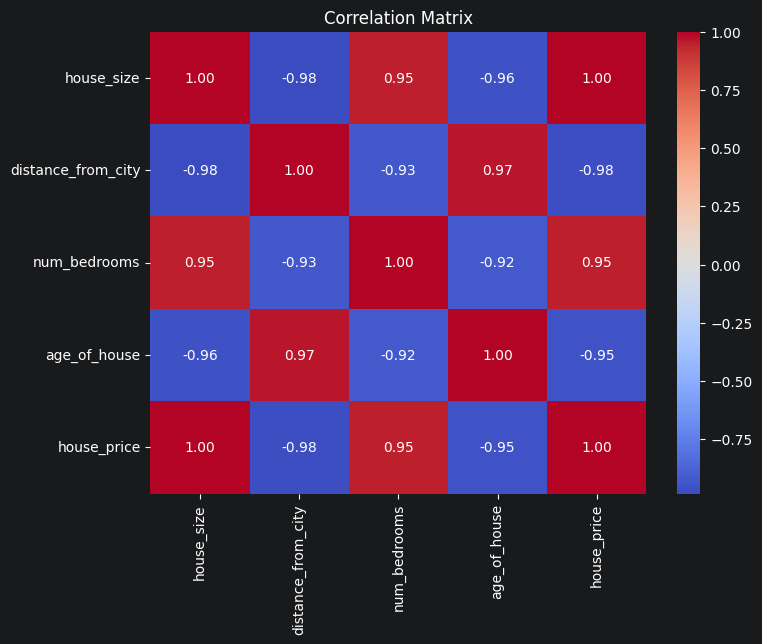

In [3]:
# Step 2 — Visualize it as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

In [4]:
# Step 3 — Extract only correlation with target
target_corr = corr_matrix['house_price'].drop('house_price').sort_values(ascending=False)
print(target_corr)

house_size            0.996333
num_bedrooms          0.946100
age_of_house         -0.947872
distance_from_city   -0.976103
Name: house_price, dtype: float64


In [5]:
from scipy import stats

# Binary target — 1 = sold within 30 days, 0 = not sold
data_ttest = {
    'house_size': [800, 1200, 1500, 1800, 2200, 900, 1600, 2000, 1100, 2500],
    'sold_fast':  [0,   0,    1,    1,    1,    0,   1,    1,    0,    1]
}

df_t = pd.DataFrame(data_ttest)

# Split into two groups based on target
group_sold     = df_t[df_t['sold_fast'] == 1]['house_size']
group_not_sold = df_t[df_t['sold_fast'] == 0]['house_size']

# Run T-Test
t_stat, p_value = stats.ttest_ind(group_sold, group_not_sold)

print(f"T-Statistic: {t_stat:.3f}")
print(f"P-Value: {p_value:.3f}")

if p_value < 0.05:
    print("house_size is statistically significant → Keep it")
else:
    print("house_size is NOT significant → Consider dropping")

T-Statistic: 4.535
P-Value: 0.002
house_size is statistically significant → Keep it
